# MumVision — Veri analizi, CNN eğitimi, test ve tekli tahmin

Bütün eğitim ve tahmin kodu bu notebook'un hücrelerindedir. Ayrı bir Python
betiği veya yerel proje modülü içe aktarılmaz. Gerekli veri `data/` klasöründedir.

Sıra: **veri analizi → temizleme → ön işleme → örnek görüntüler → model eğitimi
→ train/validation loss → test özeti ve grafikler → model kaydı → modeli yükleyip
tek görüntüde tahmin**.

VS Code'da `.venv/Scripts/python.exe` çekirdeğini seçin ve **Run All** kullanın.
Eksik paket varsa aşağıdaki kurulum hücresini bir kez çalıştırın.

Görüntüler, Binance'ten alınan gerçek sayısal fiyatlardan projede çizilmiştir;
hazır internet görselleri değildir. Model son mumda tamamlanan dokuz formasyonu
çok etiketli olarak öğrenir. Otomatik kural etiketleri uzman doğrulaması değildir;
model kutu veya finansal getiri tahmini üretmez.

### Paket kurulumu (yalnız gerekiyorsa)
Yorum işaretini kaldırarak bir kez çalıştırın; mevcut ortam hazırsa bu hücreyi geçin.

In [1]:
# %pip install -r requirements.txt

In [2]:
from pathlib import Path
from collections import OrderedDict
from dataclasses import dataclass, asdict
from datetime import datetime, timedelta, timezone
import sys
import json
import random
import time
import zipfile

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score, f1_score, hamming_loss,
    multilabel_confusion_matrix, precision_recall_curve,
    precision_recall_fscore_support, roc_auc_score, roc_curve,
)
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from IPython.display import Image, Markdown, display

# Yalnız veri klasörünü bulur; projedeki Python modüllerini içe aktarmaz.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/dataset/manifest.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Notebook'u data/ klasörünün yanındaki proje kökünden açın.")

print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "CUDA kullanılabilir:", torch.cuda.is_available())
print("Proje:", ROOT)

Python: C:\Users\sekocan\Desktop\yükseklisans-donem-2\goruntu-isleme\.venv\Scripts\python.exe
PyTorch: 2.14.1+cpu CUDA kullanılabilir: False
Proje: C:\Users\sekocan\Desktop\yükseklisans-donem-2\goruntu-isleme


### Ortak ayarlar, dosya okuma ve yardımcı fonksiyonlar
Tanımlar bu notebook içindedir. Görüntüler ZIP arşivleri çıkarılmadan okunur.

In [3]:
PATTERNS = (
    "doji", "hammer", "inverted_hammer", "hanging_man", "shooting_star",
    "bullish_engulfing", "bearish_engulfing", "morning_star", "evening_star",
)


TURKISH = (
    "Doji", "Çekiç", "Ters Çekiç", "Asılı Adam", "Kayan Yıldız",
    "Boğa Yutan", "Ayı Yutan", "Sabah Yıldızı", "Akşam Yıldızı",
)

SPLITS = {
    "train": ("2023-01-01", "2025-01-01", 0.70),
    "val": ("2025-01-01", "2025-07-01", 0.15),
    "test": ("2025-07-01", "2026-01-01", 0.15),
}

@dataclass
class TrainConfig:
    data: str = "data"
    output: str = "outputs/cnn"
    epochs: int = 20
    batch_size: int = 64
    learning_rate: float = 0.001
    patience: int = 5
    width: int = 256
    height: int = 160
    seed: int = 42
    train_limit: int = 0  # 0 = bölümün tamamı; küçük değerler yalnız akış denemesi.
    val_limit: int = 0
    test_limit: int = 0
    device: str = "auto"
    threads: int = 4


def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")


def save_figure(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return Path(path)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def choose_device(name="auto"):
    return torch.device("cuda" if torch.cuda.is_available() else "cpu") if name == "auto" else torch.device(name)

In [4]:
def read_image(path):
    result = cv2.imdecode(np.frombuffer(Path(path).read_bytes(), np.uint8), cv2.IMREAD_COLOR)
    if result is None:
        raise ValueError(f"Görüntü okunamadı: {path}")
    return result


def png_bytes(image):
    ok, buffer = cv2.imencode(".png", image, [cv2.IMWRITE_PNG_COMPRESSION, 2])
    if not ok:
        raise ValueError("PNG kodlanamadı.")
    return buffer.tobytes()


def write_image(path, image):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(png_bytes(image))

class ImageStore:
    def __init__(self, dataset_dir):
        self.root = Path(dataset_dir)
        self.name, self.archive = None, None

    def read(self, row):
        import cv2
        if row["shard"] != self.name:
            self.close()
            self.name = row["shard"]
            self.archive = zipfile.ZipFile(self.root / "shards" / self.name)
        image = cv2.imdecode(np.frombuffer(self.archive.read(row["image"]), np.uint8), cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f"Bozuk PNG: {row['image']}")
        return image

    def close(self):
        if self.archive is not None:
            self.archive.close()
            self.archive = None
        self.name = None

    def __enter__(self):
        return self

    def __exit__(self, *_):
        self.close()

## 1. Deney ayarları
İlk çalıştırmada küçük bir **akış denemesi** yapılır. Tam eğitim için
`QUICK_RUN = False` yapın: 70.000 eğitim, 15.000 validation, 15.000 test
görüntüsü kullanılır. CPU'da tam eğitim uzun sürebilir.
CUDA destekli PyTorch kuruluysa `device="auto"` GPU'yu seçer.

Her yeni deneyde farklı `RUN_NAME` kullanın. Mevcut modelin üzerine yazılmaz.
Aynı klasördeki modele eğitim yapmadan bakmak için 9. bölüm bağımsız örnektir.

Her çalıştırmada yeni bir deney klasörü otomatik oluşturulur; önceki model korunur.

In [5]:
QUICK_RUN = True
RUN_NAME = ("cnn_notebook" if QUICK_RUN else "cnn_notebook_tam") + "_" + datetime.now(timezone(timedelta(hours=3))).strftime("%Y%m%d_%H%M%S")
config = TrainConfig(
    data=str(ROOT / "data"),
    output=str(ROOT / "outputs" / RUN_NAME),
    epochs=5 if QUICK_RUN else 20,
    batch_size=32,
    learning_rate=0.001,
    patience=5,
    width=256, height=160,
    train_limit=1024 if QUICK_RUN else 0,
    val_limit=512 if QUICK_RUN else 0,
    test_limit=512 if QUICK_RUN else 0,
    device="auto",
    seed=42,
)
OUT = Path(config.output)
FIG = OUT / "figures"
print(config)

TrainConfig(data='C:\\Users\\sekocan\\Desktop\\yükseklisans-donem-2\\goruntu-isleme\\data', output='C:\\Users\\sekocan\\Desktop\\yükseklisans-donem-2\\goruntu-isleme\\outputs\\cnn_notebook_20261027_065451', epochs=5, batch_size=32, learning_rate=0.001, patience=5, width=256, height=160, seed=42, train_limit=1024, val_limit=512, test_limit=512, device='auto', threads=4)


## 2. Ham veriyi inceleme
OHLC = açılış, en yüksek, en düşük, kapanış. Hacim de kalite kontrolünde
incelenir. Fiyat CSV'leri CNN girdisi değildir; görüntü üretiminin kaynağıdır.
Bu adımda boyutlar, eksikler, veri türleri ve dağılımlar görülür.

In [6]:
manifest = pd.read_csv(Path(config.data) / "dataset" / "manifest.csv", keep_default_na=False)
raw_example = pd.read_csv(Path(config.data) / "raw" / "BTCUSDT-1h.csv.gz")
print("Manifest boyutu:", manifest.shape)
display(manifest.head())
display(raw_example.head())
display(pd.DataFrame({"dtype": raw_example.dtypes.astype(str), "missing": raw_example.isna().sum()}))
display(raw_example.describe())
display(pd.crosstab(manifest.symbol, manifest.split))

Manifest boyutu: (100000, 11)


,sample_id,split,symbol,window_start_ms,window_end_ms,shard,image,labels,objects,style,render_seed
0,train_0000000,train,ADAUSDT,1672531200000,1672614000000,train-0000.zip,images/train_0000000.png,none,3,light,42
1,train_0000001,train,BNBUSDT,1672531200000,1672614000000,train-0000.zip,images/train_0000001.png,none,5,dark,59
2,train_0000002,train,BTCUSDT,1672531200000,1672614000000,train-0000.zip,images/train_0000002.png,none,3,dark,76
3,train_0000003,train,XRPUSDT,1672531200000,1672614000000,train-0000.zip,images/train_0000003.png,none,8,dark,93
4,train_0000004,train,ADAUSDT,1672534800000,1672617600000,train-0000.zip,images/train_0000004.png,none,3,dark,110


,timestamp_ms,open,high,low,close,volume
0,1672531200000,16541.77,16545.70,16508.39,16529.67,4364.83570
1,1672534800000,16529.59,16556.80,16525.78,16551.47,3590.06669
2,1672538400000,16551.47,16559.77,16538.14,16548.19,3318.84038
3,1672542000000,16548.19,16548.19,16518.21,16533.04,4242.08050
4,1672545600000,16533.04,16535.97,16511.92,16521.85,4285.00909


,dtype,missing
timestamp_ms,int64,0
open,float64,0
high,float64,0
low,float64,0
close,float64,0
volume,float64,0


,timestamp_ms,open,high,low,close,volume
count,2.630300e+04,26303.000000,26303.000000,26303.000000,26303.000000,26303.000000
mean,1.719878e+12,65444.280129,65656.394103,65224.723129,65446.984776,2176.442239
std,2.733583e+10,31818.996455,31910.869507,31723.021346,31817.861594,4169.493907
min,1.672531e+12,16513.330000,16534.030000,16499.010000,16513.340000,0.000000
25%,1.696207e+12,30290.595000,30344.775000,30241.080000,30291.850000,547.027770
50%,1.719878e+12,64202.630000,64413.010000,63969.580000,64203.560000,946.491770
75%,1.743550e+12,95470.360000,95800.000000,95103.760000,95470.355000,1866.655850
max,1.767222e+12,126011.180000,126199.630000,125252.740000,126011.180000,80041.752040


split,test,train,val
symbol,,,
ADAUSDT,2467,11654,2475
BNBUSDT,2498,11704,2494
BTCUSDT,2497,11704,2513
ETHUSDT,2526,11695,2457
SOLUSDT,2515,11621,2529
XRPUSDT,2497,11622,2532


## 3. Temizleme, zaman kontrolü ve bölümleme
Sayısal olmayan/sonsuz değerler, geçersiz OHLC geometrisi, negatif hacim,
aynı satırın tekrarları ve çelişkili zaman kayıtları temizlenir. Eksik saatler
doldurulmaz. Temizlenmiş kopyalar `cleaned_raw/` altına yazılır.

Mevcut grafiklerden temizlemede çıkarılan veya eksik saate dokunan pencereler
elenir. Manifest tekrarları, etiketler, dosyalar ve görüntü boyutları kontrol
edilir. Seçilen tüm görüntüler gerçekten açılır; bozuklar rapora yazılır.

Bölümler rastgele yeniden bölünmez: 2023–2024 train, 2025 ilk yarı validation,
ikinci yarı test. Ham mum paylaşımı kontrol edilir. Aynı bölümdeki örtüşen
pencereler ise birbirleriyle ilişkilidir.

In [7]:
def clean_raw_data(data, output):
    """Kopyalarda temizler; eksik saatlere fiyat uydurmaz, kaynağı değiştirmez."""
    cleaned, reports = {}, []
    paths = sorted((Path(data) / "raw").glob("*-1h.csv.gz"))
    if not paths:
        raise FileNotFoundError("data/raw altında saatlik CSV yok. Önce veriyi indirin.")
    for path in paths:
        frame = pd.read_csv(path)
        columns = ["timestamp_ms", "open", "high", "low", "close", "volume"]
        numeric = frame[columns].apply(pd.to_numeric, errors="coerce")
        finite = np.isfinite(numeric).all(axis=1)
        valid = (finite & (numeric[["open", "high", "low", "close"]] > 0).all(axis=1)
                 & (numeric.volume >= 0) & (numeric.high >= numeric[["open", "close", "low"]].max(axis=1))
                 & (numeric.low <= numeric[["open", "close", "high"]].min(axis=1))
                 & (numeric.timestamp_ms % 3_600_000 == 0))
        good = numeric.loc[valid].copy()
        exact_duplicates = int(good.duplicated().sum())
        good = good.drop_duplicates()
        conflicts = good.timestamp_ms.duplicated(keep=False)
        conflict_rows = int(conflicts.sum())
        good = good.loc[~conflicts].sort_values("timestamp_ms").reset_index(drop=True)
        good["timestamp_ms"] = good.timestamp_ms.astype("int64")
        symbol = path.name.split("-1h")[0]
        cleaned[symbol] = good
        good.to_csv(output / "cleaned_raw" / path.name, index=False, compression="gzip")
        delta = np.diff(good.timestamp_ms.to_numpy())
        reports.append({"symbol": symbol, "before": len(frame), "invalid_rows": int((~valid).sum()),
                        "exact_duplicates_removed": exact_duplicates, "conflicting_rows_removed": conflict_rows,
                        "after": len(good), "gap_count": int((delta != 3_600_000).sum()),
                        "missing_hours": int(np.maximum(delta // 3_600_000 - 1, 0).sum())})
    report = pd.DataFrame(reports)
    report.to_csv(output / "raw_cleaning.csv", index=False)
    pd.concat([f.assign(symbol=s) for s, f in cleaned.items()]).describe(include="all").to_csv(output / "raw_describe.csv")
    return cleaned, report


def labels_from_rows(rows):
    return np.asarray([[name in text.split("|") for name in PATTERNS] for text in rows.labels], dtype=np.float32)

In [8]:
def preprocess(image_bgr, size):
    """RGB, (width,height) resize, float32 /255, CHW. Eğitim ve predict ortaktır."""
    rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, tuple(size), interpolation=cv2.INTER_AREA)
    return torch.from_numpy(np.ascontiguousarray(resized.transpose(2, 0, 1))).float().div_(255)


def examples_figure(rows, config):
    # Yalnız eğitim örnekleri; mümkünse her sınıftan bir pozitif göster.
    indices = []
    y = labels_from_rows(rows)
    for k in range(len(PATTERNS)):
        candidates = np.flatnonzero(y[:, k])
        if len(candidates):
            indices.append(int(candidates[0]))
    indices = list(dict.fromkeys(indices))
    indices += [i for i in range(len(rows)) if i not in indices][:9 - len(indices)]
    fig, axes = plt.subplots(3, 3, figsize=(14, 9))
    with ImageStore(Path(config.data) / "dataset") as store:
        for ax, i in zip(axes.flat, indices):
            row = rows.iloc[i]
            image = store.read(row)
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            ax.set_title(row.labels, fontsize=8)
        for ax in axes.flat:
            ax.axis("off")
        image = store.read(rows.iloc[0])
    save_figure(fig, Path(config.output) / "figures" / "training_examples.png")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Orijinal RGB: 512 × 320")
    tensor = preprocess(image, (config.width, config.height))
    axes[1].imshow(tensor.permute(1, 2, 0).numpy())
    axes[1].set_title(f"Model girdisi: {config.width} × {config.height}, [0,1]")
    for ax in axes:
        ax.axis("off")
    save_figure(fig, Path(config.output) / "figures" / "preprocessing.png")

In [9]:
def prepare_data(config):
    """Ham analiz/temizleme, pencere doğrulama, görüntü kontrolü, EDA."""
    data, output = Path(config.data), Path(config.output)
    if min(config.epochs, config.batch_size, config.patience, config.threads) < 1:
        raise ValueError("Epoch, batch_size, patience ve threads pozitif olmalı.")
    if min(config.width, config.height) < 32 or config.learning_rate <= 0:
        raise ValueError("Görüntü kenarları en az 32; learning_rate pozitif olmalı.")
    if min(config.train_limit, config.val_limit, config.test_limit) < 0:
        raise ValueError("Örnek sınırları negatif olamaz.")
    if (output / "best_model.pt").exists():
        raise FileExistsError(f"Bu deneyde model zaten var: {output}. Yeni bir output / RUN_NAME seçin; mevcut deneyin ayarları korunur.")
    output.mkdir(parents=True, exist_ok=True)
    (output / "cleaned_raw").mkdir(exist_ok=True)
    (output / "figures").mkdir(exist_ok=True)
    raw, raw_report = clean_raw_data(data, output)
    rows = pd.read_csv(data / "dataset" / "manifest.csv", keep_default_na=False)
    original_count = len(rows)
    # Kaynak dizinin yerine çıktı dizininde temizlenmiş manifest oluşturulur.
    reason = pd.Series("", index=rows.index)
    required = ["sample_id", "split", "symbol", "shard", "image", "labels"]
    reason.loc[(rows[required] == "").any(axis=1)] = "missing_field"
    reason.loc[~rows.split.isin(SPLITS)] = "unknown_split"
    reason.loc[rows.duplicated("sample_id", keep=False) | rows.duplicated(["symbol", "window_end_ms"], keep=False)] = "duplicate_id_or_window"
    allowed = set(PATTERNS)
    valid_label = rows.labels.map(lambda t: t == "none" or (len(t.split("|")) == len(set(t.split("|"))) and set(t.split("|")) <= allowed))
    reason.loc[~valid_label] = "invalid_labels"
    for col in ("window_start_ms", "window_end_ms"):
        rows[col] = pd.to_numeric(rows[col], errors="coerce")
    metadata = json.loads((data / "dataset" / "metadata.json").read_text(encoding="utf-8"))
    if metadata["classes"] != list(PATTERNS):
        raise ValueError("Veri sınıf sırası model sınıflarıyla uyuşmuyor.")
    window = int(metadata["window"])
    duration_ok = ((rows.window_end_ms - rows.window_start_ms) == (window - 1) * 3_600_000)
    reason.loc[~duration_ok] = "invalid_window_duration"
    for symbol, group in rows.groupby("symbol"):
        if symbol not in raw:
            reason.loc[group.index] = "missing_raw_symbol"
            continue
        ts = raw[symbol].timestamp_ms.to_numpy()
        starts = group.window_start_ms.to_numpy()
        ends = group.window_end_ms.to_numpy()
        a, b = np.searchsorted(ts, starts), np.searchsorted(ts, ends)
        if not len(ts):
            reason.loc[group.index] = "empty_clean_raw"
            continue
        aa, bb = np.minimum(a, len(ts) - 1), np.minimum(b, len(ts) - 1)
        gaps = np.r_[0, np.cumsum(np.diff(ts) != 3_600_000)]
        valid = ((a < len(ts)) & (b < len(ts)) & (ts[aa] == starts) & (ts[bb] == ends)
                 & (b - a == window - 1) & (gaps[aa] == gaps[bb]))
        reason.loc[group.index[~valid]] = "window_contains_removed_or_missing_raw"
    for split, (start, end, _) in SPLITS.items():
        mask = rows.split == split
        lo = pd.Timestamp(start, tz="UTC").value // 1_000_000
        hi = pd.Timestamp(end, tz="UTC").value // 1_000_000
        reason.loc[mask & ~((rows.window_start_ms >= lo) & (rows.window_end_ms < hi))] = "outside_split_dates"
    rejected = rows.loc[reason != ""].assign(reason=reason[reason != ""])
    rejected.to_csv(output / "rejected_manifest.csv", index=False)
    clean = rows.loc[reason == ""].copy()
    clean.to_csv(output / "clean_manifest.csv", index=False)
    parts = {}
    image_errors = []
    for split in SPLITS:
        part = clean.loc[clean.split == split]
        limit = getattr(config, f"{split}_limit")
        if limit:
            part = part.sample(min(limit, len(part)), random_state=config.seed)
        part = part.sort_values(["shard", "sample_id"])
        valid_indices = []
        with ImageStore(data / "dataset") as store:
            for index, row in part.iterrows():
                try:
                    image = store.read(row)
                    if image.shape != (metadata["image_size"][1], metadata["image_size"][0], 3):
                        raise ValueError(f"Beklenmeyen boyut: {image.shape}")
                    valid_indices.append(index)
                except (OSError, ValueError, KeyError, RuntimeError, zipfile.BadZipFile) as exc:
                    image_errors.append({"sample_id": row.sample_id, "reason": str(exc)})
        part = part.loc[valid_indices].reset_index(drop=True)
        if part.empty:
            raise ValueError(f"{split} bölümünde kullanılabilir örnek yok.")
        parts[split] = part
        print(f"{split}: {len(part):,} görüntü doğrulandı", flush=True)
    for first, second in (("train", "val"), ("val", "test")):
        if parts[first].window_end_ms.max() >= parts[second].window_start_ms.min():
            raise ValueError("Bölümler arasında ham mum paylaşımı var.")
    pd.DataFrame(image_errors, columns=["sample_id", "reason"]).to_csv(output / "rejected_images.csv", index=False)
    used = pd.concat(parts.values(), ignore_index=True)
    used.to_csv(output / "used_manifest.csv", index=False)
    class_counts = pd.DataFrame({s: labels_from_rows(p).sum(axis=0).astype(int) for s, p in parts.items()}, index=PATTERNS)
    class_counts.to_csv(output / "class_counts.csv")
    pd.crosstab(used.symbol, used.split).to_csv(output / "symbol_counts.csv")
    report = {"manifest_before": original_count, "manifest_after": len(clean),
              "manifest_rejected": len(rejected), "image_rejected": len(image_errors),
              "used_sizes": {s: len(p) for s, p in parts.items()}, "cross_split_overlap": False,
              "quick_run": any(getattr(config, f"{s}_limit") for s in SPLITS),
              "image_check_scope": "Only selected images; full splits when limits are zero",
              "cleaning_note": "No imputation. Existing rendered windows touching removed/missing raw rows are excluded.",
              "zero_train_support": class_counts.index[class_counts.train == 0].tolist(),
              "zero_val_support": class_counts.index[class_counts.val == 0].tolist()}
    save_json(output / "data_report.json", report)
    save_json(output / "config.json", asdict(config))
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    class_counts.plot.bar(ax=axes[0], logy=True, title="Son mum: pozitif etiket sayısı (log)")
    pd.crosstab(used.symbol, used.split).plot.bar(ax=axes[1], title="Varlık / bölüm")
    used.groupby([pd.to_datetime(used.window_end_ms, unit="ms", utc=True).dt.strftime("%Y-%m"), "split"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axes[2], title="Kronolojik dağılım")
    save_figure(fig, output / "figures" / "data_distribution.png")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for symbol, frame in raw.items():
        if not frame.empty:
            axes[0].plot(pd.to_datetime(frame.timestamp_ms, unit="ms", utc=True), frame.close / frame.close.iloc[0], label=symbol, linewidth=.6)
    axes[0].set_title("Temizlenmiş kapanış / ilk kapanış")
    axes[0].legend(fontsize=7)
    raw_report.set_index("symbol")[["invalid_rows", "exact_duplicates_removed", "conflicting_rows_removed", "gap_count"]].plot.bar(ax=axes[1], title="Temizleme ve saat boşlukları")
    save_figure(fig, output / "figures" / "raw_analysis.png")
    examples_figure(parts["train"], config)
    print(raw_report.to_string(index=False), flush=True)
    print(class_counts.to_string(), flush=True)
    if report["zero_train_support"]:
        print("UYARI: Eğitimde pozitif örneği olmayan sınıflar:", report["zero_train_support"], flush=True)
    return parts, report

In [10]:
parts, data_report = prepare_data(config)
display(pd.read_csv(OUT / "raw_cleaning.csv"))
display(pd.Series(data_report, name="Değer").to_frame())
display(pd.read_csv(OUT / "class_counts.csv", index_col=0))

train: 1,024 görüntü doğrulandı


val: 512 görüntü doğrulandı


test: 512 görüntü doğrulandı


 symbol  before  invalid_rows  exact_duplicates_removed  conflicting_rows_removed  after  gap_count  missing_hours
ADAUSDT   26303             0                         0                         0  26303          1              1
BNBUSDT   26303             0                         0                         0  26303          1              1
BTCUSDT   26303             0                         0                         0  26303          1              1
ETHUSDT   26303             0                         0                         0  26303          1              1
SOLUSDT   26303             0                         0                         0  26303          1              1
XRPUSDT   26303             0                         0                         0  26303          1              1


                   train  val  test
doji                 106   39    60
hammer                14   10     8
inverted_hammer        2    3     1
hanging_man            7    8     2
shooting_star          9    7     7
bullish_engulfing     30   14    11
bearish_engulfing     37   17    20
morning_star           4    4     2
evening_star           5    2     0


,symbol,before,invalid_rows,exact_duplicates_removed,conflicting_rows_removed,after,gap_count,missing_hours
0,ADAUSDT,26303,0,0,0,26303,1,1
1,BNBUSDT,26303,0,0,0,26303,1,1
2,BTCUSDT,26303,0,0,0,26303,1,1
3,ETHUSDT,26303,0,0,0,26303,1,1
4,SOLUSDT,26303,0,0,0,26303,1,1
5,XRPUSDT,26303,0,0,0,26303,1,1


,Değer
manifest_before,100000
manifest_after,100000
manifest_rejected,0
image_rejected,0
used_sizes,"{'train': 1024, 'val': 512, 'test': 512}"
cross_split_overlap,False
quick_run,True
image_check_scope,Only selected images; full splits when limits ...
cleaning_note,No imputation. Existing rendered windows touch...
zero_train_support,[]


,train,val,test
doji,106,39,60
hammer,14,10,8
inverted_hammer,2,3,1
hanging_man,7,8,2
shooting_star,9,7,7
bullish_engulfing,30,14,11
bearish_engulfing,37,17,20
morning_star,4,4,2
evening_star,5,2,0


## 4. Dağılımlar ve örnek görüntüler
Sınıf dengesizliğini, eksik saatleri, tarihleri ve çizim stillerini inceleyin.
Galeride yalnız eğitim örnekleri gösterilir. Nadir bir sınıf denemede hiç
bulunmayabilir; bu durum `data_report.json` içinde açıkça raporlanır.

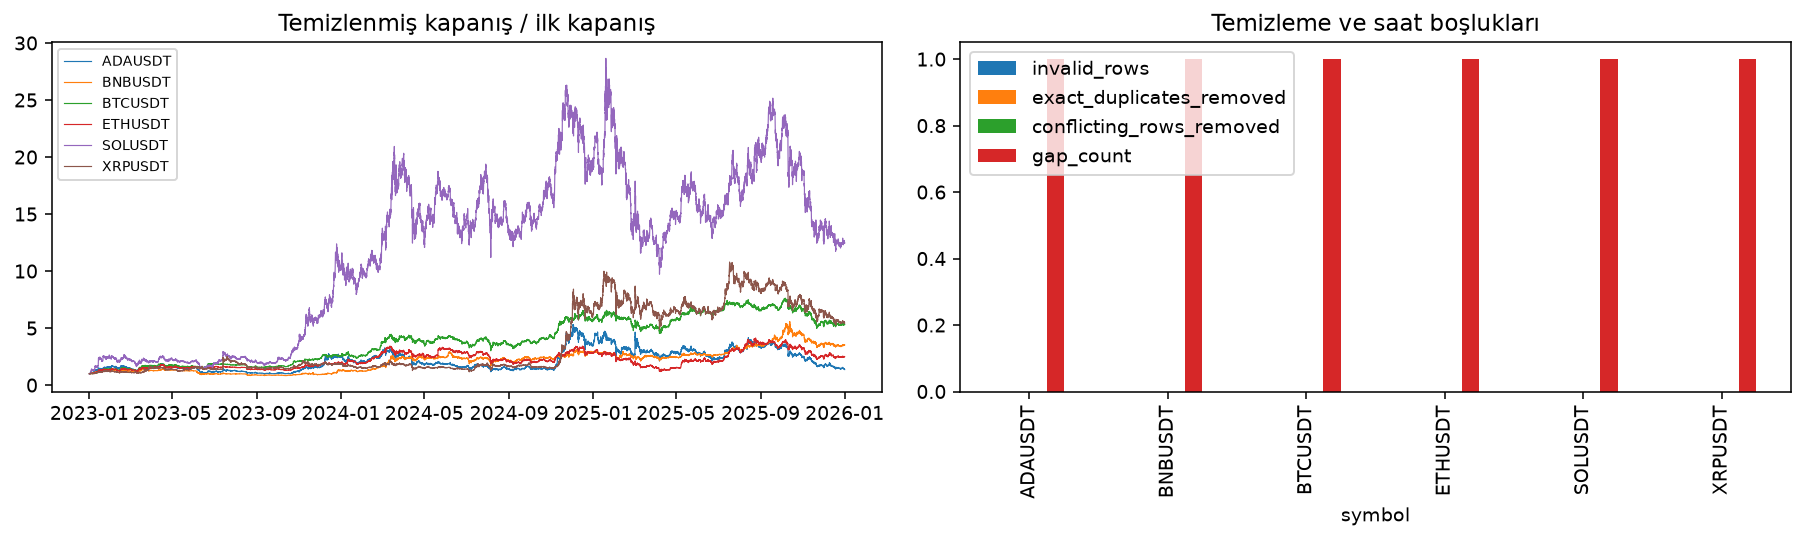

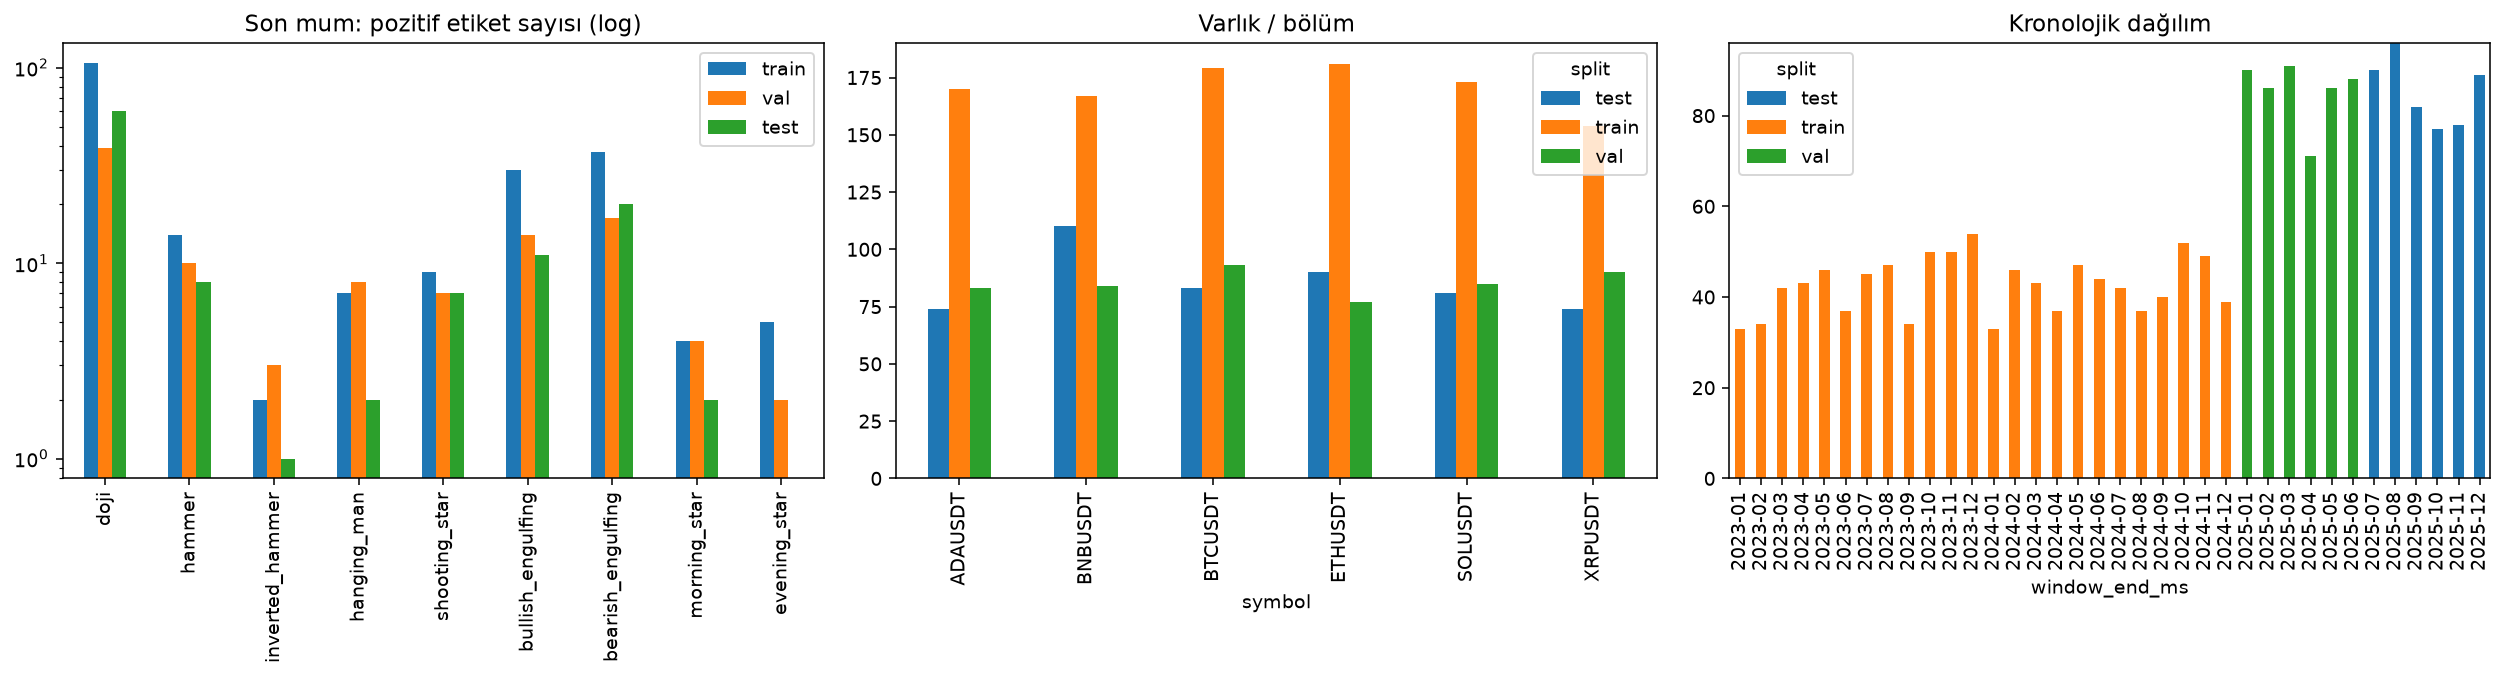

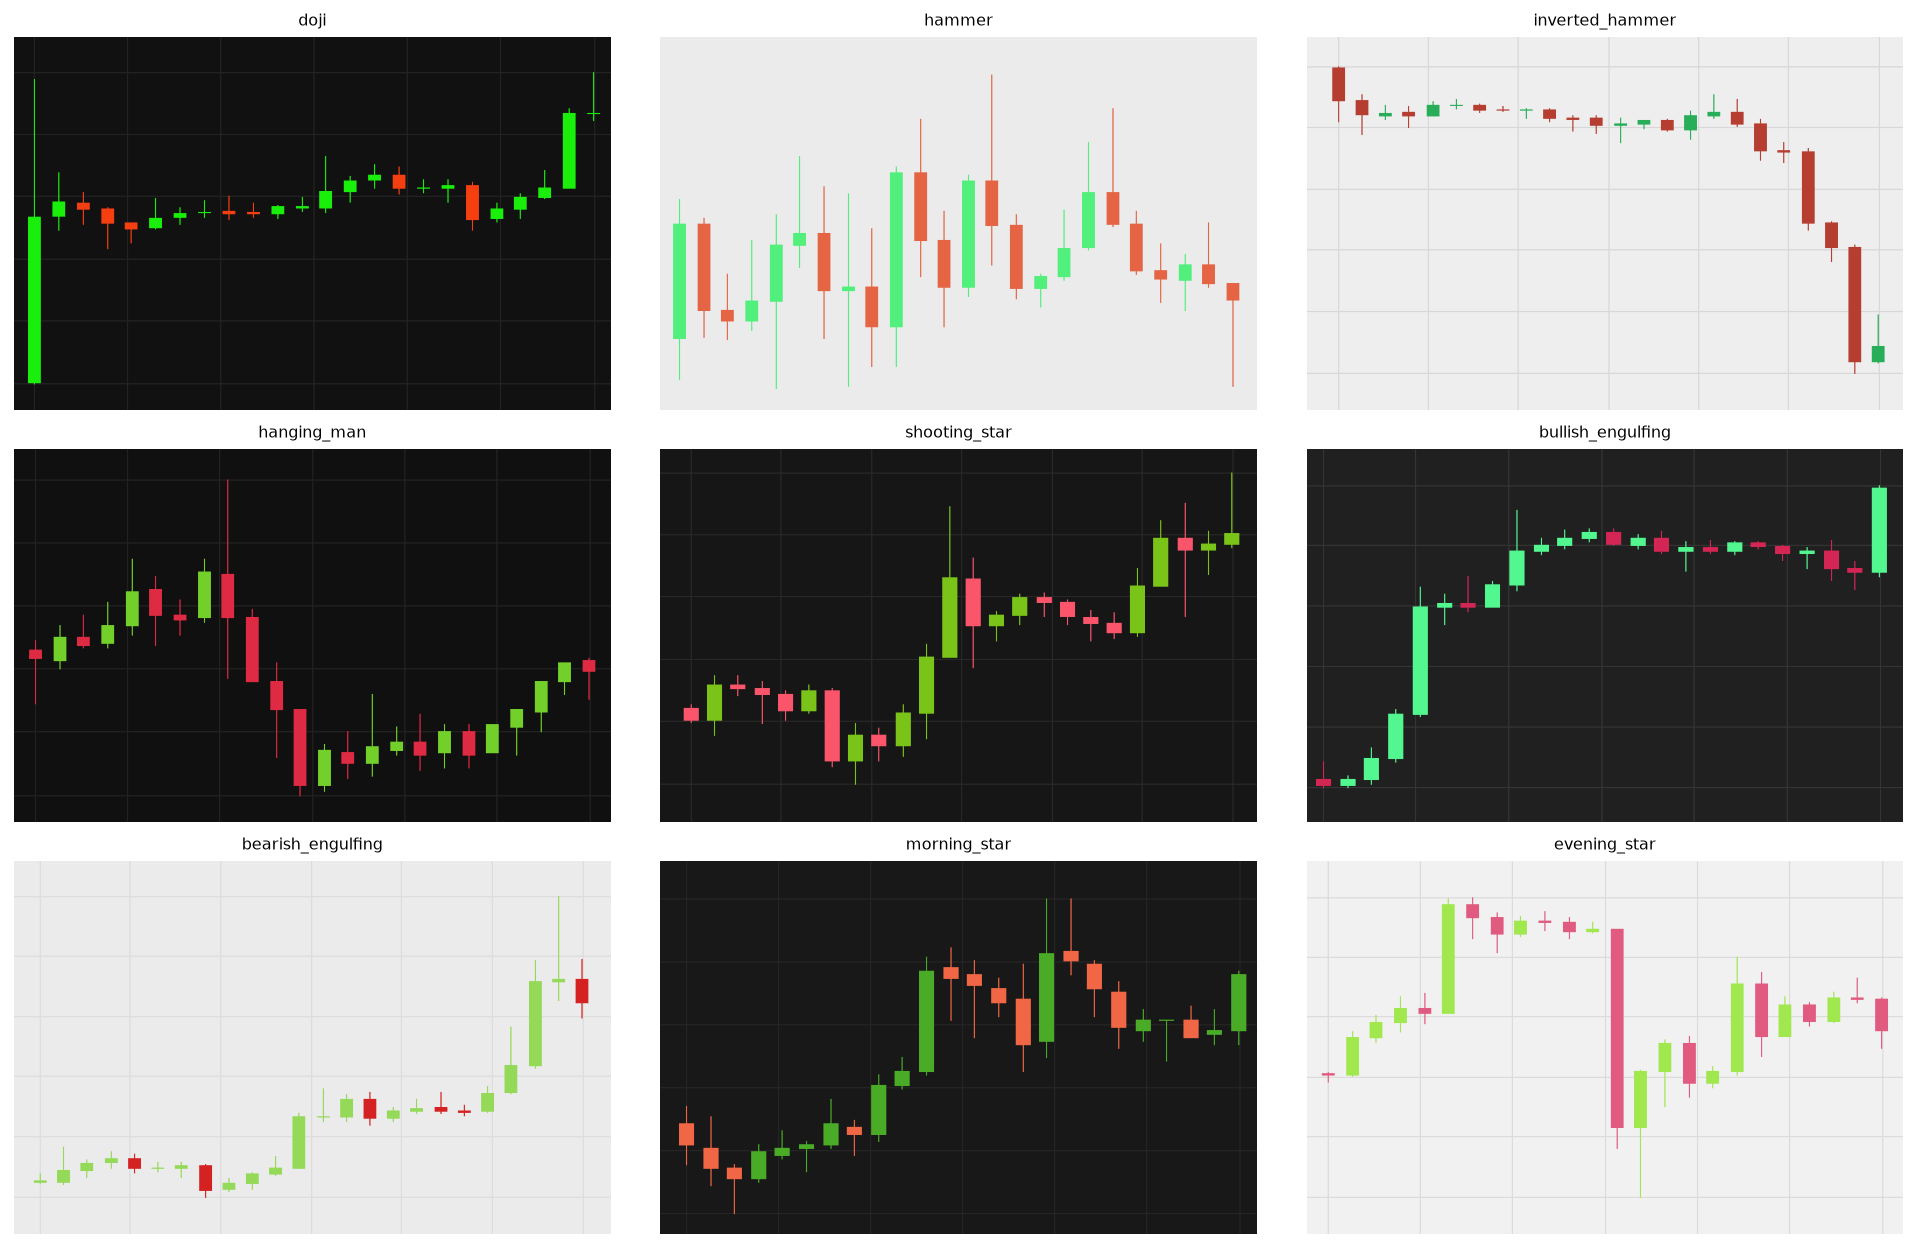

In [11]:
display(Image(filename=str(FIG / "raw_analysis.png")))
display(Image(filename=str(FIG / "data_distribution.png")))
display(Image(filename=str(FIG / "training_examples.png")))

## 5. Görüntü ön işleme ve model mimarisi
OpenCV BGR → RGB → 256×160 → float32 [0,1] → CHW tensor.
Aynı fonksiyon eğitimde ve tekli tahminde kullanılır. Fiyat yönünü/formasyonu
değiştiren çevirme, döndürme veya rastgele kırpma uygulanmaz.
İnce fitiller küçültmede kaybolabilir; daha ayrıntılı deney için width=512,
height=320 seçilebilir (daha çok bellek ve süre gerekir).

CNN: üç convolution/ReLU/pooling bloğu, konumu koruyan 5×8 havuzlama,
128 nöronlu katman, dropout ve 9 logit. Softmax yerine sigmoid kullanılır.

In [12]:
class ChartDataset(Dataset):
    """ZIP'leri çıkartmadan okur; Windows notebook için workers=0 kullanılır."""
    def __init__(self, root, rows, size):
        self.root, self.rows, self.size = Path(root), rows.reset_index(drop=True), size
        self.targets = labels_from_rows(self.rows)
        self.archives = OrderedDict()

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        name = row.shard
        if name not in self.archives:
            self.archives[name] = zipfile.ZipFile(self.root / "shards" / name)
        self.archives.move_to_end(name)
        while len(self.archives) > 64:
            self.archives.popitem(last=False)[1].close()
        image = cv2.imdecode(np.frombuffer(self.archives[name].read(row.image), dtype=np.uint8), cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f"Bozuk görüntü: {row.sample_id}")
        return preprocess(image, self.size), torch.from_numpy(self.targets[index])

    def close(self):
        for archive in self.archives.values():
            archive.close()
        self.archives.clear()


class CandleCNN(nn.Module):
    """Konumsal bilgiyi koruyan küçük CNN; 9 bağımsız logit üretir."""
    def __init__(self, classes=len(PATTERNS)):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((5, 8)),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 5 * 8, 128), nn.ReLU(), nn.Dropout(.25), nn.Linear(128, classes))

    def forward(self, x):
        return self.head(self.features(x))


def make_loader(config, rows, shuffle=False):
    ds = ChartDataset(Path(config.data) / "dataset", rows, (config.width, config.height))
    generator = torch.Generator().manual_seed(config.seed)
    return DataLoader(ds, batch_size=config.batch_size, shuffle=shuffle, num_workers=0, generator=generator)

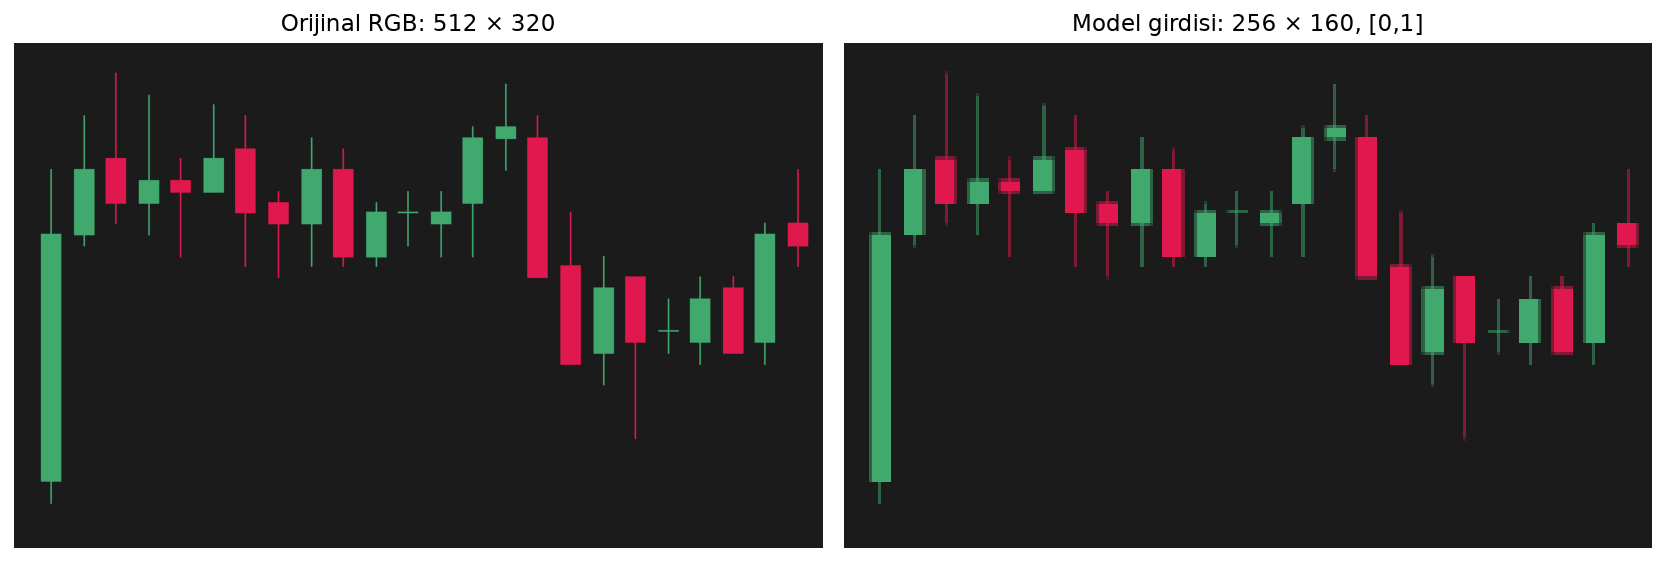

CandleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(5, 8))
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=9, bias=True)
  )
)
Öğrenilebilir parametre: 352553
Tensor: torch.Size([3, 160, 256]) torch.float32 min/max: 0.0941176488995552 0.8784313797950745


In [13]:
display(Image(filename=str(FIG / "preprocessing.png")))
model_preview = CandleCNN()
print(model_preview)
print("Öğrenilebilir parametre:", sum(p.numel() for p in model_preview.parameters()))
row = parts["train"].iloc[0]
with ImageStore(Path(config.data) / "dataset") as store:
    tensor = preprocess(store.read(row), (config.width, config.height))
print("Tensor:", tensor.shape, tensor.dtype, "min/max:", tensor.min().item(), tensor.max().item())

## 6. Model eğitimi ve en iyi modeli kaydetme
Adam + BCEWithLogitsLoss kullanılır. Pozitif sınıf ağırlıkları yalnız eğitim
verisinden hesaplanır; en fazla 30 ile sınırlandırılır. Train ve validation
loss aynı ağırlıklarla ölçülür. En düşük validation loss'taki ağırlıklar
`best_model.pt` olarak kaydedilir. Patience dolarsa early stopping uygulanır.

Test verisi bu aşamada kullanılmaz. Loss ve sabit 0.5 eşikli F1 her epoch'ta
`history.csv` dosyasına yazılır. Tekrar eğitim için RUN_NAME'i değiştirin.

In [14]:
def run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, truths, probabilities = 0., [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            if not torch.isfinite(loss):
                raise FloatingPointError("Loss sonlu değil; eğitim durduruldu.")
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += float(loss.detach()) * len(x)
            truths.append(y.detach().cpu().numpy())
            probabilities.append(logits.detach().sigmoid().cpu().numpy())
    return loss_sum / len(loader.dataset), np.concatenate(truths).astype(int), np.concatenate(probabilities)


def train_model(config, parts):
    output, device = Path(config.output), choose_device(config.device)
    checkpoint_path = output / "best_model.pt"
    if checkpoint_path.exists():
        raise FileExistsError(f"Model zaten var: {checkpoint_path}. Yeni deney için farklı output seçin.")
    seed_everything(config.seed)
    torch.set_num_threads(config.threads)
    model = CandleCNN().to(device)
    positives = labels_from_rows(parts["train"]).sum(axis=0)
    # Yalnız eğitim bölümünden öğrenilen ağırlıklar; loss ölçeği train/val/test'te aynı.
    weights = np.clip((len(parts["train"]) - positives) / np.maximum(positives, 1), 1, 30).astype(np.float32)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weights, device=device))
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    train_loader, val_loader = make_loader(config, parts["train"], True), make_loader(config, parts["val"])
    (output / "model_summary.txt").write_text(str(model) + f"\nParameters: {sum(p.numel() for p in model.parameters()):,}\nDevice: {device}", encoding="utf-8")
    save_json(output / "environment.json", {"torch": str(torch.__version__), "numpy": np.__version__, "device": str(device)})
    history, best, stale = [], float("inf"), 0
    print(f"Eğitim aygıtı: {device}; {config.epochs} epoch; çıktı: {output}", flush=True)
    try:
        for epoch in range(1, config.epochs + 1):
            begin = time.perf_counter()
            tl, ty, tp = run_epoch(model, train_loader, criterion, device, optimizer)
            vl, vy, vp = run_epoch(model, val_loader, criterion, device)
            history.append({"epoch": epoch, "train_loss": tl, "val_loss": vl,
                            "train_micro_f1": float(f1_score(ty, tp >= .5, average="micro", zero_division=0)),
                            "val_micro_f1": float(f1_score(vy, vp >= .5, average="micro", zero_division=0)),
                            "seconds": time.perf_counter() - begin})
            pd.DataFrame(history).to_csv(output / "history.csv", index=False)
            print(f"Epoch {epoch:02d}: loss={tl:.4f}, val_loss={vl:.4f}, val_F1={history[-1]['val_micro_f1']:.4f}, {history[-1]['seconds']:.1f}s", flush=True)
            if vl < best - 1e-6:
                best, stale = vl, 0
                torch.save({"format_version": 1, "architecture": "CandleCNN", "state_dict": model.state_dict(),
                            "classes": list(PATTERNS), "image_size": [config.width, config.height],
                            "thresholds": [.5] * len(PATTERNS), "pos_weight": weights.tolist(),
                            "best_epoch": epoch, "best_val_loss": best, "config": asdict(config),
                            "target": "Patterns completed at the last candle; multi-label, no bounding boxes"}, checkpoint_path)
            else:
                stale += 1
                if stale >= config.patience:
                    print("Early stopping: validation loss iyileşmedi.", flush=True)
                    break
    finally:
        train_loader.dataset.close()
        val_loader.dataset.close()
    history = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.epoch, history.train_loss, label="Train loss")
    axes[0].plot(history.epoch, history.val_loss, label="Validation loss")
    axes[0].set_title("Aynı sınıf ağırlıklarıyla BCE loss")
    axes[0].axvline(int(history.loc[history.val_loss.idxmin(), "epoch"]), color="gray", linestyle="--", label="Kaydedilen epoch")
    axes[1].plot(history.epoch, history.train_micro_f1, label="Train micro F1")
    axes[1].plot(history.epoch, history.val_micro_f1, label="Validation micro F1")
    axes[1].set_title("Epoch F1 (sabit eşik=0.5)")
    axes[1].set_ylim(0, 1)
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
    save_figure(fig, output / "figures" / "learning_curves.png")
    return checkpoint_path, history

In [15]:
def load_model(checkpoint_path, device="cpu"):
    device = choose_device(device)
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    if checkpoint["architecture"] != "CandleCNN" or checkpoint["classes"] != list(PATTERNS):
        raise ValueError("Model mimarisi veya sınıf sırası desteklenmiyor.")
    model = CandleCNN(len(checkpoint["classes"])).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, checkpoint

Eğitim aygıtı: cpu; 5 epoch; çıktı: C:\Users\sekocan\Desktop\yükseklisans-donem-2\goruntu-isleme\outputs\cnn_notebook_20261027_065451


Epoch 01: loss=0.8986, val_loss=0.8977, val_F1=0.0550, 13.6s


Epoch 02: loss=0.8017, val_loss=0.9074, val_F1=0.1266, 11.7s


Epoch 03: loss=0.8087, val_loss=0.9103, val_F1=0.0481, 11.5s


Epoch 04: loss=0.7946, val_loss=0.8947, val_F1=0.0447, 11.7s


Epoch 05: loss=0.7699, val_loss=0.8862, val_F1=0.0000, 11.7s


,epoch,train_loss,val_loss,train_micro_f1,val_micro_f1,seconds
0,1,0.898569,0.897731,0.068129,0.054965,13.635998
1,2,0.801688,0.907364,0.085620,0.126623,11.651089
2,3,0.808658,0.910292,0.117326,0.048077,11.536262
3,4,0.794615,0.894678,0.094199,0.044709,11.675277
4,5,0.769945,0.886187,0.091354,0.000000,11.673073


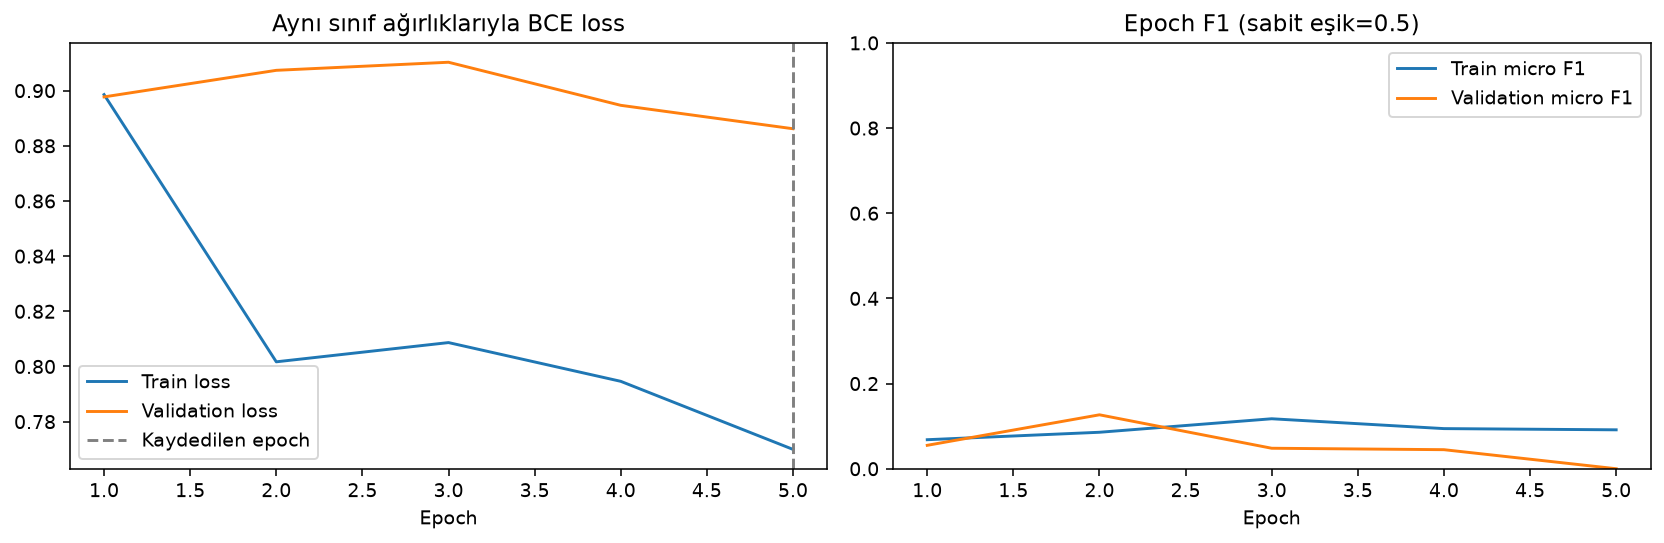

Kaydedilen model: C:\Users\sekocan\Desktop\yükseklisans-donem-2\goruntu-isleme\outputs\cnn_notebook_20261027_065451\best_model.pt


In [16]:
checkpoint_path, history = train_model(config, parts)
display(history)
display(Image(filename=str(FIG / "learning_curves.png")))
print("Kaydedilen model:", checkpoint_path)

## 7. Validation eşikleri ve son test
En iyi model tekrar yüklenir. Her sınıfın sigmoid eşiği yalnız validation
F1 değerine göre seçilir. Validation'da tek etiket değeri olan sınıfın eşiği
0.5 kalır. Eşikler modele kaydedildikten sonra test bölümü değerlendirilir.

Çok etiketli problemde sıradan accuracy tek başına yeterli değildir:
micro/macro F1, precision, recall, exact match, Hamming loss, AP ve ROC AUC
raporlanır. Her zaman `none` diyen temel yöntemle de karşılaştırılır.

In [17]:
def select_thresholds(truth, probabilities):
    thresholds = []
    for k in range(len(PATTERNS)):
        if len(np.unique(truth[:, k])) < 2:
            thresholds.append(.5)  # Validation'da karşılaştırma yoksa ayarlama yapılmaz.
            continue
        grid = np.linspace(.05, .95, 37)
        scores = [f1_score(truth[:, k], probabilities[:, k] >= t, zero_division=0) for t in grid]
        candidates = np.flatnonzero(np.isclose(scores, max(scores)))
        best = candidates[np.argmin(np.abs(grid[candidates] - .5))]
        thresholds.append(round(float(grid[best]), 3))
    return np.asarray(thresholds)


def metric_summary(truth, predicted):
    return {"micro_f1": float(f1_score(truth, predicted, average="micro", zero_division=0)),
            "macro_f1": float(f1_score(truth, predicted, average="macro", zero_division=0)),
            "exact_match": float(np.all(truth == predicted, axis=1).mean()),
            "hamming_loss": float(hamming_loss(truth, predicted))}

In [18]:
def evaluation_figures(config, truth, probabilities, predicted, table, rows):
    folder = Path(config.output) / "figures"
    fig, ax = plt.subplots(figsize=(12, 5))
    table.set_index("class")[["precision", "recall", "f1"]].plot.bar(ax=ax)
    ax.set_ylim(0, 1.05)
    ax.set_title("Test: sınıf bazında precision / recall / F1")
    save_figure(fig, folder / "test_class_metrics.png")
    fig, axes = plt.subplots(3, 3, figsize=(12, 11))
    for k, ax in enumerate(axes.flat):
        matrix = multilabel_confusion_matrix(truth, predicted)[k]
        ax.imshow(matrix, cmap="Blues")
        for (i, j), value in np.ndenumerate(matrix):
            ax.text(j, i, str(value), ha="center", va="center", color="red")
        ax.set_xticks([0, 1], ["Yok", "Var"])
        ax.set_yticks([0, 1], ["Yok", "Var"])
        ax.set_xlabel("Tahmin")
        ax.set_ylabel("Gerçek (kural)")
        ax.set_title(TURKISH[k])
    save_figure(fig, folder / "confusion_matrices.png")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for k, name in enumerate(PATTERNS):
        if len(np.unique(truth[:, k])) == 2:
            p, r, _ = precision_recall_curve(truth[:, k], probabilities[:, k])
            axes[0].plot(r, p, label=f"{name} AP={table.average_precision.iloc[k]:.2f}")
            fp, tp, _ = roc_curve(truth[:, k], probabilities[:, k])
            axes[1].plot(fp, tp, label=f"{name} AUC={table.roc_auc.iloc[k]:.2f}")
    axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall (nadir sınıflar için önemli)")
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
    axes[1].plot([0, 1], [0, 1], "k--")
    for ax in axes:
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.05)
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=6)
    save_figure(fig, folder / "pr_roc_curves.png")
    errors = np.flatnonzero(np.any(truth != predicted, axis=1)).tolist()
    correct = np.flatnonzero(np.all(truth == predicted, axis=1)).tolist()
    chosen = errors[:6] + correct[:3]
    fig, axes = plt.subplots(3, 3, figsize=(15, 10))
    with ImageStore(Path(config.data) / "dataset") as store:
        for ax, i in zip(axes.flat, chosen):
            ax.imshow(cv2.cvtColor(store.read(rows.iloc[i]), cv2.COLOR_BGR2RGB))
            names = "|".join(n for n, v in zip(PATTERNS, predicted[i]) if v) or "none"
            ax.set_title(f"Gerçek: {rows.iloc[i].labels}\nTahmin: {names}", fontsize=7, color="red" if i in errors else "green")
        for ax in axes.flat:
            ax.axis("off")
    save_figure(fig, folder / "test_examples_and_errors.png")

In [19]:
def evaluate_model(config, parts, checkpoint_path):
    """Eşikler yalnız validation'da seçilir, ardından test bir kez değerlendirilir."""
    output, device = Path(config.output), choose_device(config.device)
    model, checkpoint = load_model(checkpoint_path, str(device))
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(checkpoint["pos_weight"], device=device))
    val_loader, test_loader = make_loader(config, parts["val"]), make_loader(config, parts["test"])
    try:
        _, vy, vp = run_epoch(model, val_loader, criterion, device)
        thresholds = select_thresholds(vy, vp)
        checkpoint["thresholds"] = thresholds.tolist()
        checkpoint["threshold_source"] = "Validation per-class F1 grid; test never used"
        torch.save(checkpoint, checkpoint_path)
        test_loss, truth, probabilities = run_epoch(model, test_loader, criterion, device)
    finally:
        val_loader.dataset.close()
        test_loader.dataset.close()
    predicted = probabilities >= thresholds
    precision, recall, f1, support = precision_recall_fscore_support(truth, predicted, average=None, zero_division=0)
    ap, auc = [], []
    for k in range(len(PATTERNS)):
        ap.append(float(average_precision_score(truth[:, k], probabilities[:, k])) if truth[:, k].any() else None)
        auc.append(float(roc_auc_score(truth[:, k], probabilities[:, k])) if len(np.unique(truth[:, k])) == 2 else None)
    table = pd.DataFrame({"class": PATTERNS, "precision": precision, "recall": recall, "f1": f1,
                          "support": support, "average_precision": ap, "roc_auc": auc, "threshold": thresholds})
    table.to_csv(output / "test_per_class.csv", index=False)
    summary = {"test_images": len(truth), "test_loss": test_loss, "best_epoch": checkpoint["best_epoch"],
               **metric_summary(truth, predicted), "always_none_baseline": metric_summary(truth, np.zeros_like(truth)),
               "quick_run": any(getattr(config, f"{s}_limit") for s in SPLITS),
               "threshold_source": checkpoint["threshold_source"],
               "interpretation": "Agreement with rule-generated weak labels, not expert accuracy or return forecasting.",
               "task": checkpoint["target"]}
    save_json(output / "test_metrics.json", summary)
    save_json(output / "thresholds.json", dict(zip(PATTERNS, thresholds.tolist())))
    details = parts["test"][["sample_id", "symbol", "labels"]].copy()
    details["prediction"] = ["|".join(n for n, v in zip(PATTERNS, row) if v) or "none" for row in predicted]
    details["exact_match"] = np.all(truth == predicted, axis=1)
    for k, name in enumerate(PATTERNS):
        details[f"prob_{name}"] = probabilities[:, k]
    details.to_csv(output / "test_predictions.csv", index=False)
    np.savez_compressed(output / "test_probabilities.npz", truth=truth, probabilities=probabilities, thresholds=thresholds)
    evaluation_figures(config, truth, probabilities, predicted, table, parts["test"])
    lines = ["# CNN test özeti", "", f"En iyi epoch: {checkpoint['best_epoch']} (validation loss ile).",
             f"Test görüntüsü: {len(truth):,}; test loss: {test_loss:.4f}.",
             f"Micro F1: {summary['micro_f1']:.4f}; macro F1: {summary['macro_f1']:.4f}; exact match: {summary['exact_match']:.4f}.",
             f"Her zaman none diyen karşılaştırmanın exact match değeri: {summary['always_none_baseline']['exact_match']:.4f}.",
             "", "Eşikler validation bölümünde sınıf bazında seçildi. Testte eşik veya model seçilmedi.",
             "Bu model son mumdaki etiketleri öğrenir; kutu üretmez. Etiketler otomatik OHLC kurallarındandır.",
             "Aynı bölümde örtüşen pencereler bulunduğundan örnekler bağımsız değildir.",
             ""]
    if summary["quick_run"]:
        lines += ["Bu çalışma sınırlı örnekle AKIŞ DENEMESİDİR; tam veri başarısı olarak raporlanmamalıdır.", ""]
    lines += ["Sınıf bazında sonuçlar: test_per_class.csv. Grafikler: figures/.",
              "Kayıt: best_model.pt (ağırlıklar, sınıf sırası, giriş boyutu ve validation eşikleri)."]
    (output / "TEST_OZETI.md").write_text("\n".join(lines), encoding="utf-8")
    print(json.dumps(summary, ensure_ascii=False, indent=2), flush=True)
    return summary, table

In [20]:
test_summary, per_class = evaluate_model(config, parts, checkpoint_path)
display(pd.Series(test_summary, name="Sonuç").to_frame())
display(per_class)
display(Markdown((OUT / "TEST_OZETI.md").read_text(encoding="utf-8")))

{
  "test_images": 512,
  "test_loss": 0.7762285266071558,
  "best_epoch": 5,
  "micro_f1": 0.06908768821966342,
  "macro_f1": 0.04460564456355677,
  "exact_match": 0.0,
  "hamming_loss": 0.4561631944444444,
  "always_none_baseline": {
    "micro_f1": 0.0,
    "macro_f1": 0.0,
    "exact_match": 0.787109375,
    "hamming_loss": 0.024088541666666668
  },
  "quick_run": true,
  "threshold_source": "Validation per-class F1 grid; test never used",
  "interpretation": "Agreement with rule-generated weak labels, not expert accuracy or return forecasting.",
  "task": "Patterns completed at the last candle; multi-label, no bounding boxes"
}


,Sonuç
test_images,512
test_loss,0.776229
best_epoch,5
micro_f1,0.069088
macro_f1,0.044606
exact_match,0.0
hamming_loss,0.456163
always_none_baseline,"{'micro_f1': 0.0, 'macro_f1': 0.0, 'exact_matc..."
quick_run,True
threshold_source,Validation per-class F1 grid; test never used


,class,precision,recall,f1,support,average_precision,roc_auc,threshold
0,doji,0.117188,1.000000,0.209790,60,0.145928,0.495796,0.475
1,hammer,0.043478,0.125000,0.064516,8,0.019737,0.434772,0.450
2,inverted_hammer,0.021739,1.000000,0.042553,1,0.142857,0.988258,0.175
3,hanging_man,0.004405,1.000000,0.008772,2,0.015301,0.710784,0.200
4,shooting_star,0.019231,0.571429,0.037209,7,0.121293,0.636775,0.300
5,bullish_engulfing,0.019724,0.909091,0.038610,11,0.024859,0.432226,0.400
6,bearish_engulfing,0.000000,0.000000,0.000000,20,0.040148,0.479878,0.475
7,morning_star,0.000000,0.000000,0.000000,2,0.004548,0.360784,0.250
8,evening_star,0.000000,0.000000,0.000000,0,NaN,NaN,0.225


# CNN test özeti

En iyi epoch: 5 (validation loss ile).
Test görüntüsü: 512; test loss: 0.7762.
Micro F1: 0.0691; macro F1: 0.0446; exact match: 0.0000.
Her zaman none diyen karşılaştırmanın exact match değeri: 0.7871.

Eşikler validation bölümünde sınıf bazında seçildi. Testte eşik veya model seçilmedi.
Bu model son mumdaki etiketleri öğrenir; kutu üretmez. Etiketler otomatik OHLC kurallarındandır.
Aynı bölümde örtüşen pencereler bulunduğundan örnekler bağımsız değildir.

Bu çalışma sınırlı örnekle AKIŞ DENEMESİDİR; tam veri başarısı olarak raporlanmamalıdır.

Sınıf bazında sonuçlar: test_per_class.csv. Grafikler: figures/.
Kayıt: best_model.pt (ağırlıklar, sınıf sırası, giriş boyutu ve validation eşikleri).

## 8. Önemli test grafikleri ve hatalar
Her sınıf için ayrı 2×2 confusion matrix kullanılır; tek 9×9 matris çok
etiketli yapıyı doğru anlatmaz. PR eğrisi nadir sınıflarda özellikle yararlıdır.
Testte pozitif örneği olmayan sınıfın AP'si ve tek değerli sınıfın ROC AUC'si
tanımsızdır; bunlar boş bırakılır. Hatalara bakarak bu test üzerinde yeniden
eşik seçmeyin; yeni seçimler validation'da yapılmalıdır.

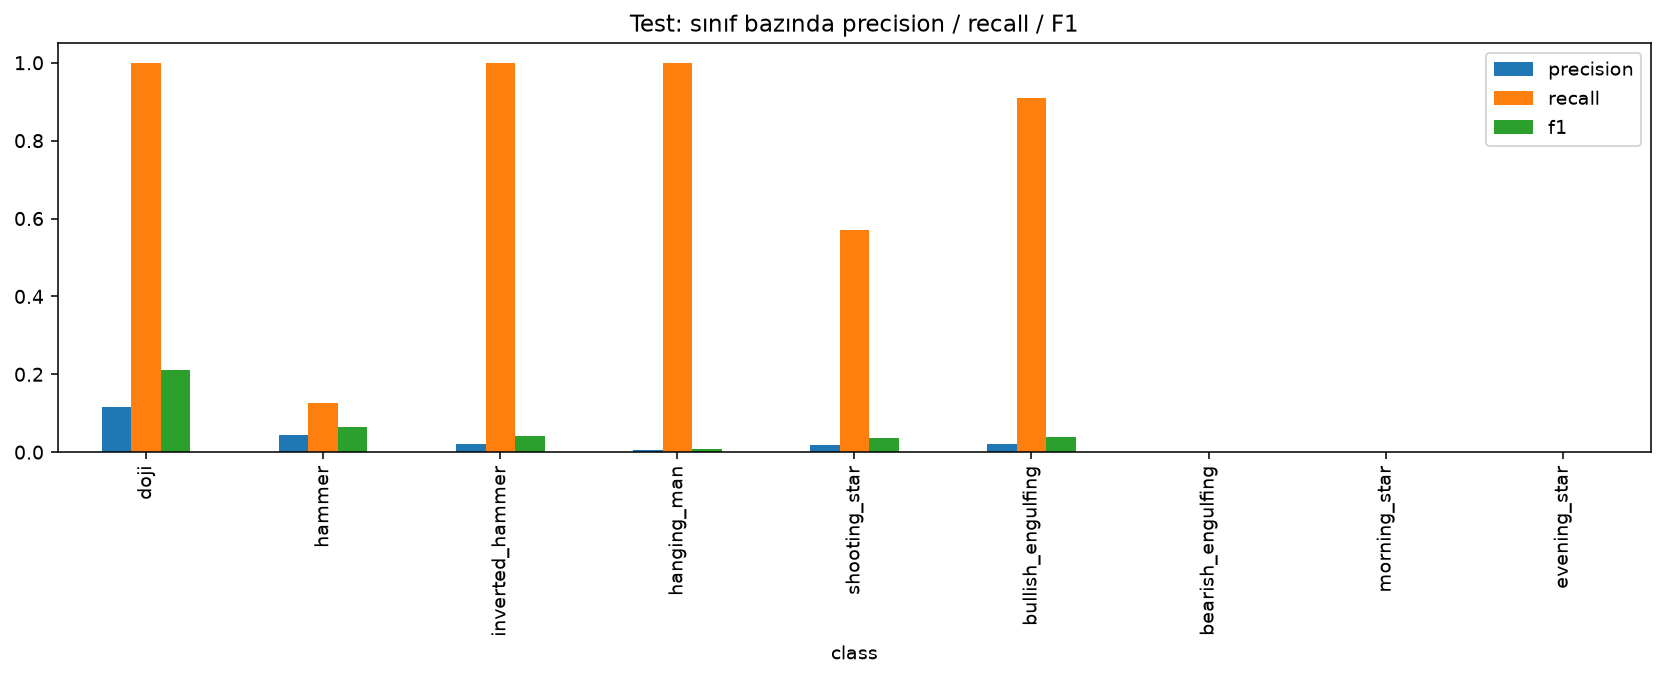

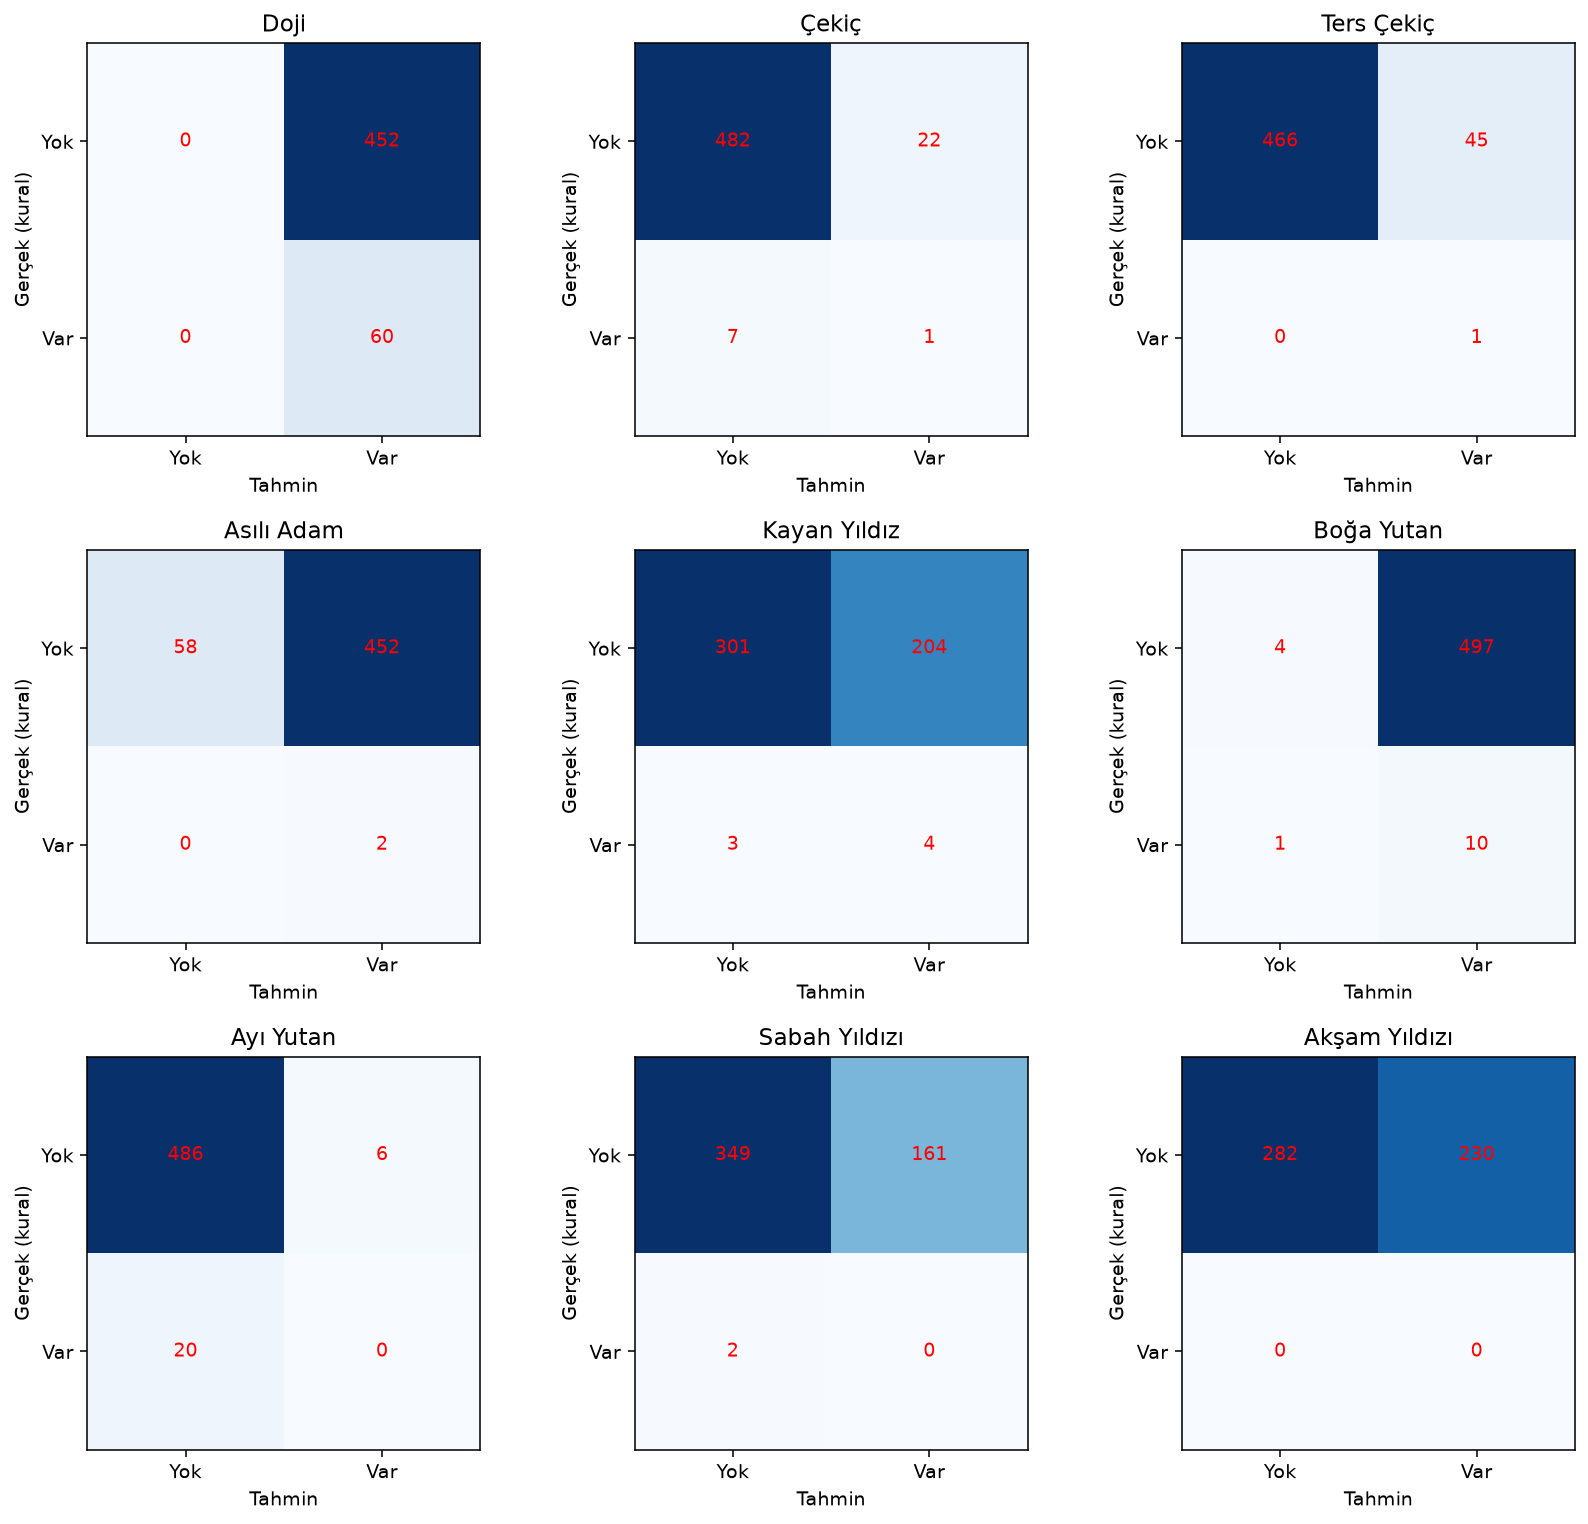

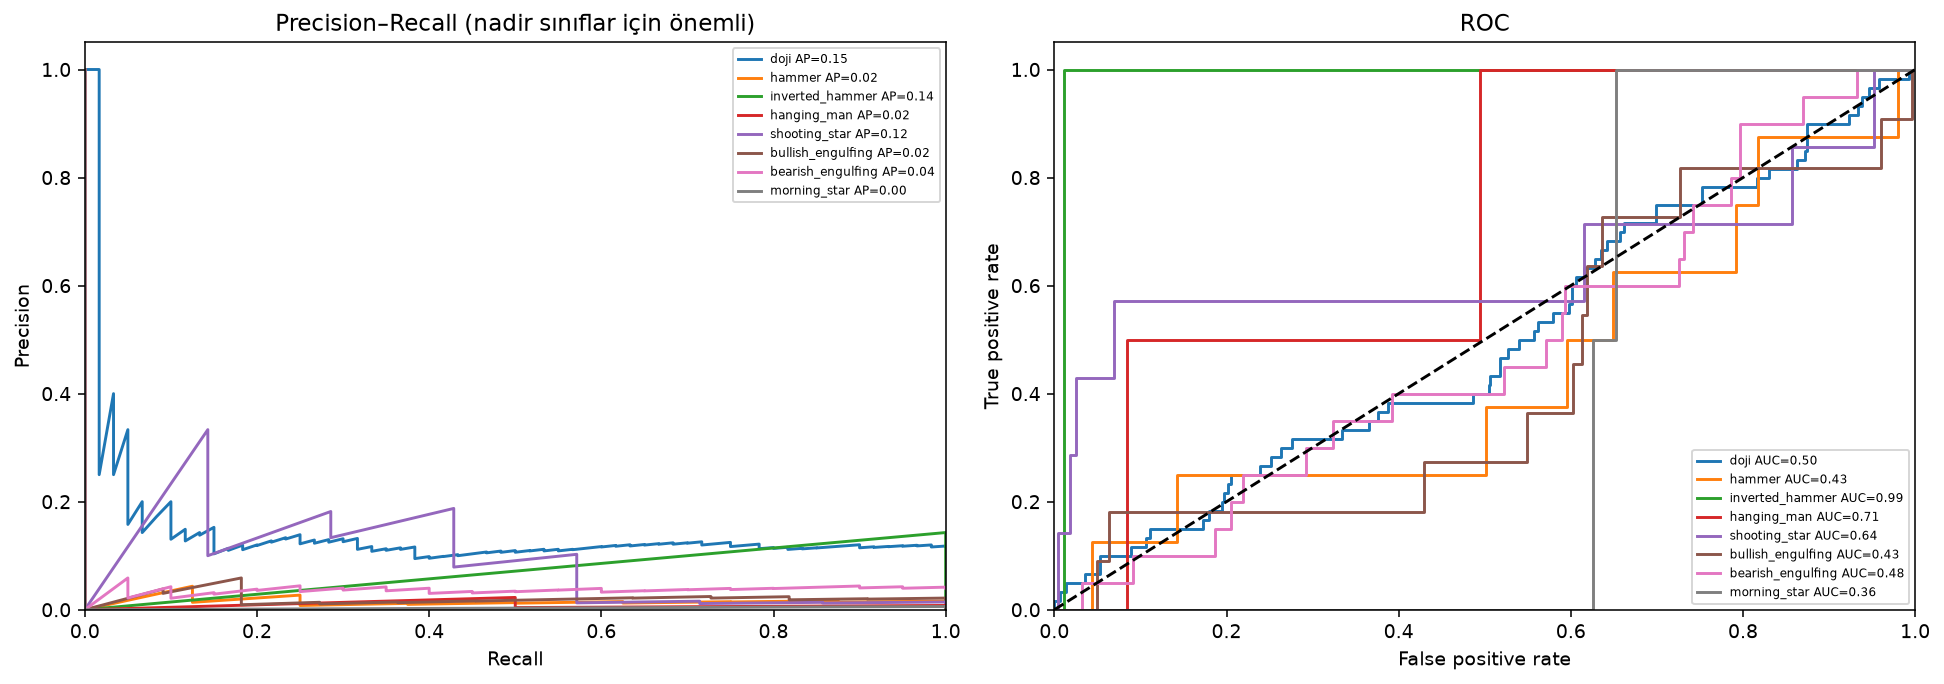

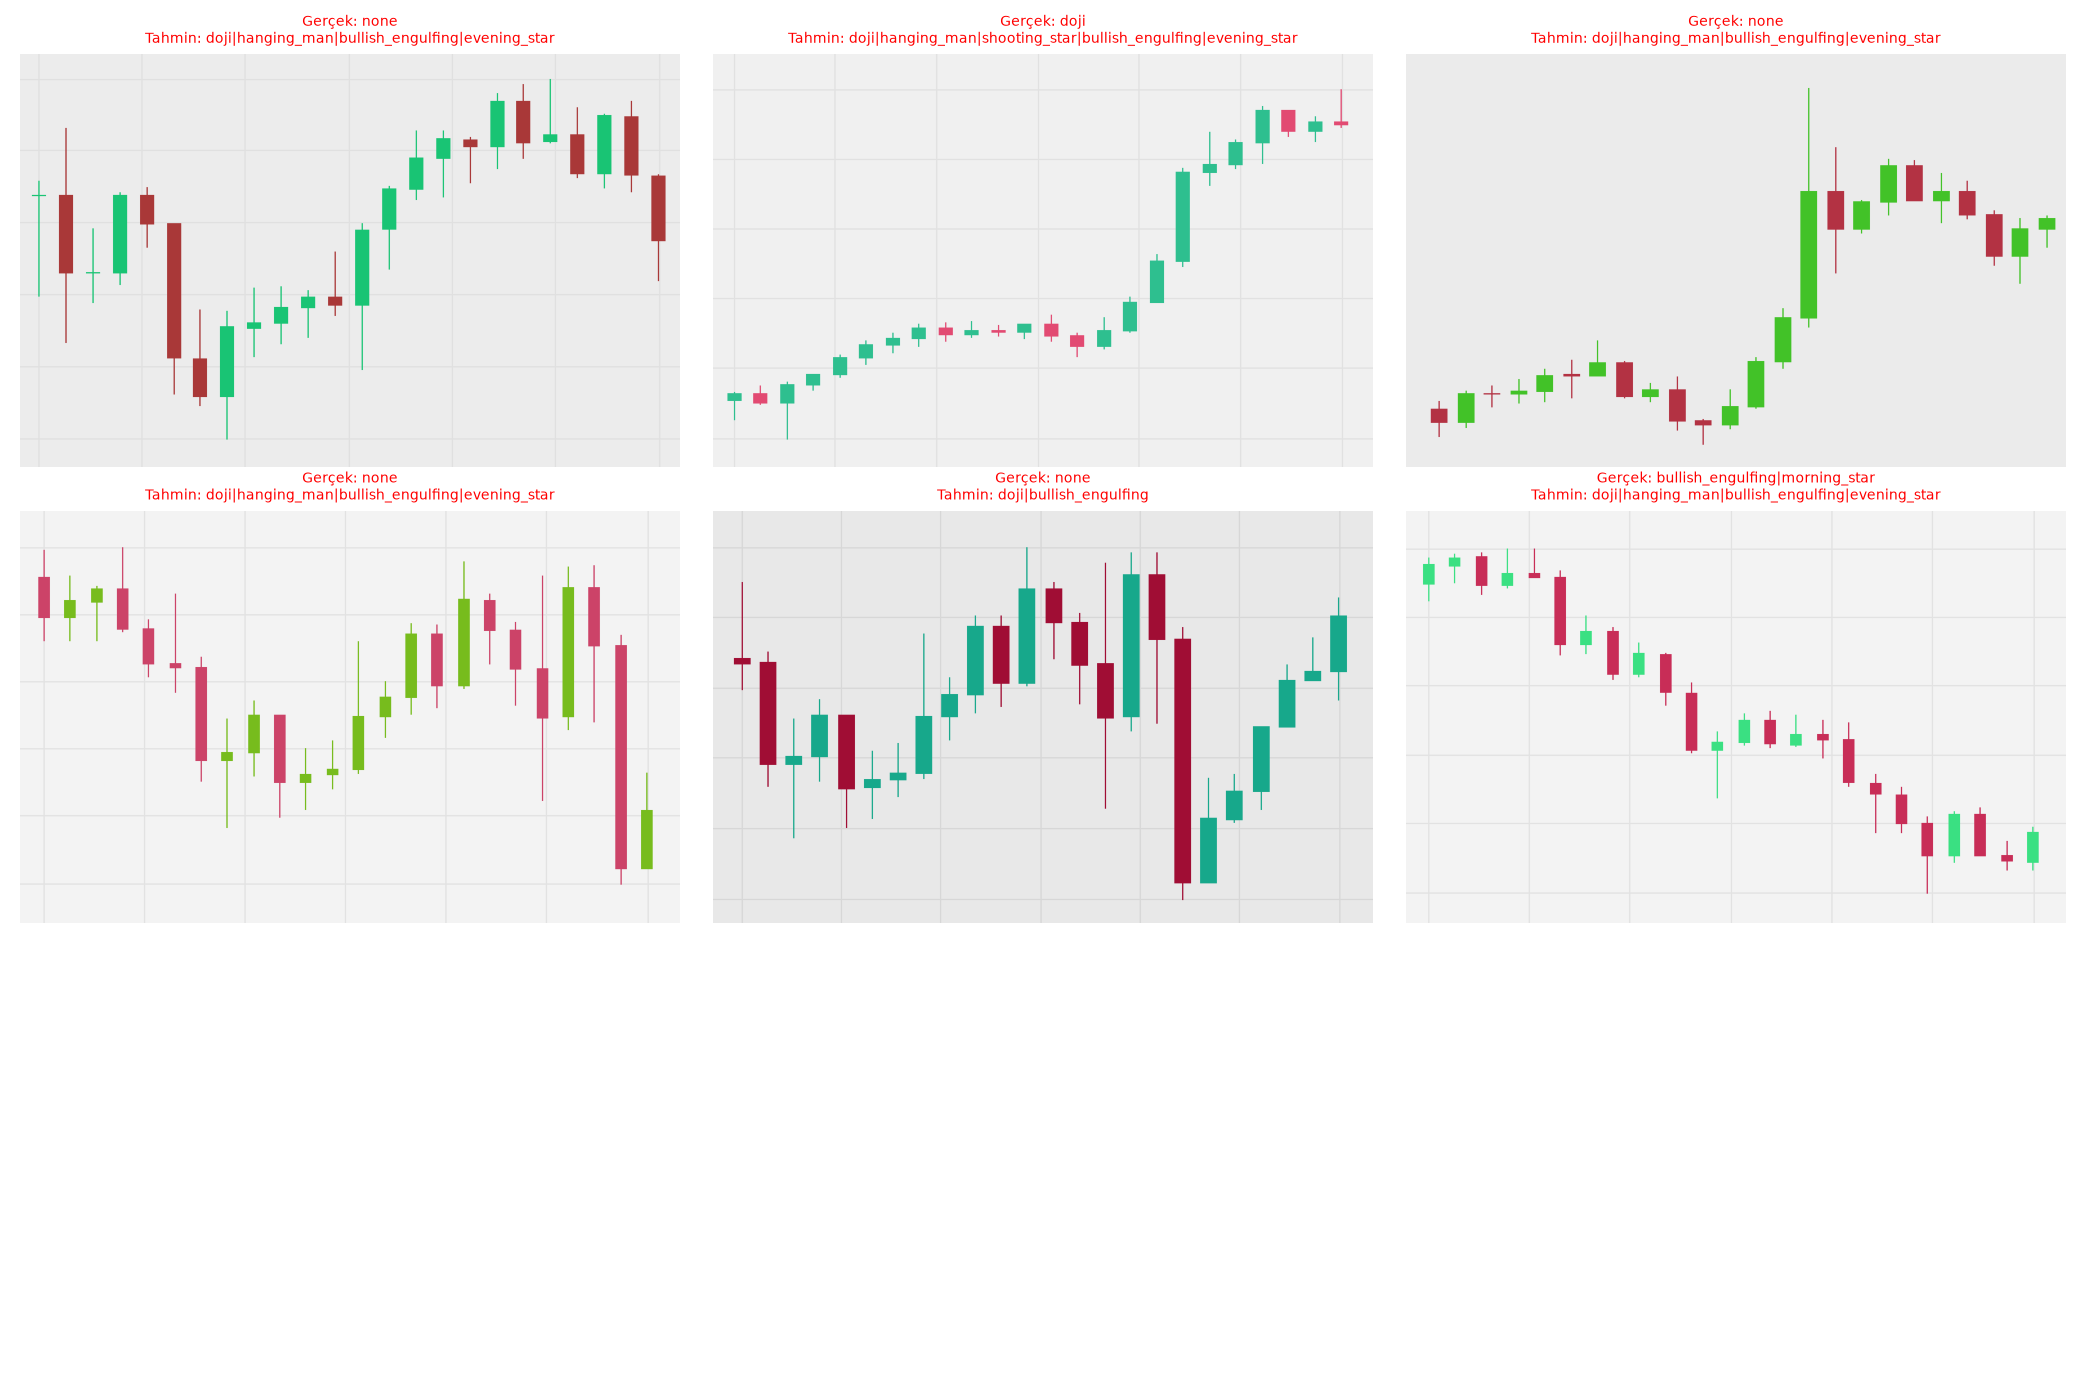

In [21]:
for name in ("test_class_metrics.png", "confusion_matrices.png", "pr_roc_curves.png", "test_examples_and_errors.png"):
    display(Image(filename=str(FIG / name)))

## 9. Modeli diskten yükle ve tek görüntüde predict et

Aşağıdaki fonksiyonlar, modeli diskteki ağırlıklarıyla yükler ve eğitimdeki
RGB/resize/normalizasyon adımlarını aynen uygular. CSV/gerçek etiket okunmaz.
Skorlar kalibre edilmiş güven yüzdesi değildir.

Örnek görüntü son testten alınır; model ve eşikler bu aşamadan önce dondurulmuştur.
Girdi yalnız fiyat paneli, 24 mum, kırmızı/yeşil dolu mumlar ve doğrusal eksen
olmalıdır. Farklı platform ekran görüntülerinde başarı ayrıca ölçülmelidir.

In [22]:
def predict_image(checkpoint_path, image_path, device="cpu"):
    """Diske kayıtlı model yüklenir; CSV, gerçek etiket veya OHLC kullanılmaz."""
    model, checkpoint = load_model(checkpoint_path, device)
    image = read_image(image_path)
    x = preprocess(image, checkpoint["image_size"]).unsqueeze(0).to(next(model.parameters()).device)
    with torch.inference_mode():
        probabilities = model(x).sigmoid()[0].cpu().numpy()
    table = pd.DataFrame({"class": checkpoint["classes"], "score": probabilities,
                          "threshold": checkpoint["thresholds"]})
    table["predicted"] = table.score >= table.threshold
    return {"image": str(image_path), "labels": table.loc[table.predicted, "class"].tolist() or ["none"],
            "scores": table.to_dict(orient="records"), "target": checkpoint["target"]}


def export_prediction_example(config, parts, checkpoint_path):
    path = Path(config.output) / "single_input.png"
    # Model ve eşikler dondurulduktan sonra testten tek örnek görselleştirilir.
    candidates = parts["test"].loc[parts["test"].labels != "none"]
    row = candidates.iloc[0] if len(candidates) else parts["test"].iloc[0]
    with ImageStore(Path(config.data) / "dataset") as store:
        write_image(path, store.read(row))
    result = predict_image(checkpoint_path, path)
    save_json(Path(config.output) / "single_prediction.json", result)
    scores = pd.DataFrame(result["scores"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].imshow(cv2.cvtColor(read_image(path), cv2.COLOR_BGR2RGB))
    axes[0].set_title("Tahmin: " + ", ".join(result["labels"]))
    axes[0].axis("off")
    axes[1].barh(scores["class"], scores.score, label="Sigmoid skoru")
    axes[1].scatter(scores.threshold, np.arange(len(scores)), c="red", marker="|", label="Validation eşiği")
    axes[1].set_xlim(0, 1)
    axes[1].legend()
    save_figure(fig, Path(config.output) / "figures" / "single_prediction.png")
    return result

Yüklenen epoch: 5
Sınıflar: ['doji', 'hammer', 'inverted_hammer', 'hanging_man', 'shooting_star', 'bullish_engulfing', 'bearish_engulfing', 'morning_star', 'evening_star']
Giriş boyutu: [256, 160]
Tahmin: ['doji', 'hanging_man', 'shooting_star', 'bullish_engulfing', 'evening_star']


,class,score,threshold,predicted
0,doji,0.491018,0.475,True
1,hammer,0.395448,0.450,False
2,inverted_hammer,0.166970,0.175,False
3,hanging_man,0.230541,0.200,True
4,shooting_star,0.303648,0.300,True
5,bullish_engulfing,0.419227,0.400,True
6,bearish_engulfing,0.467627,0.475,False
7,morning_star,0.182197,0.250,False
8,evening_star,0.255348,0.225,True


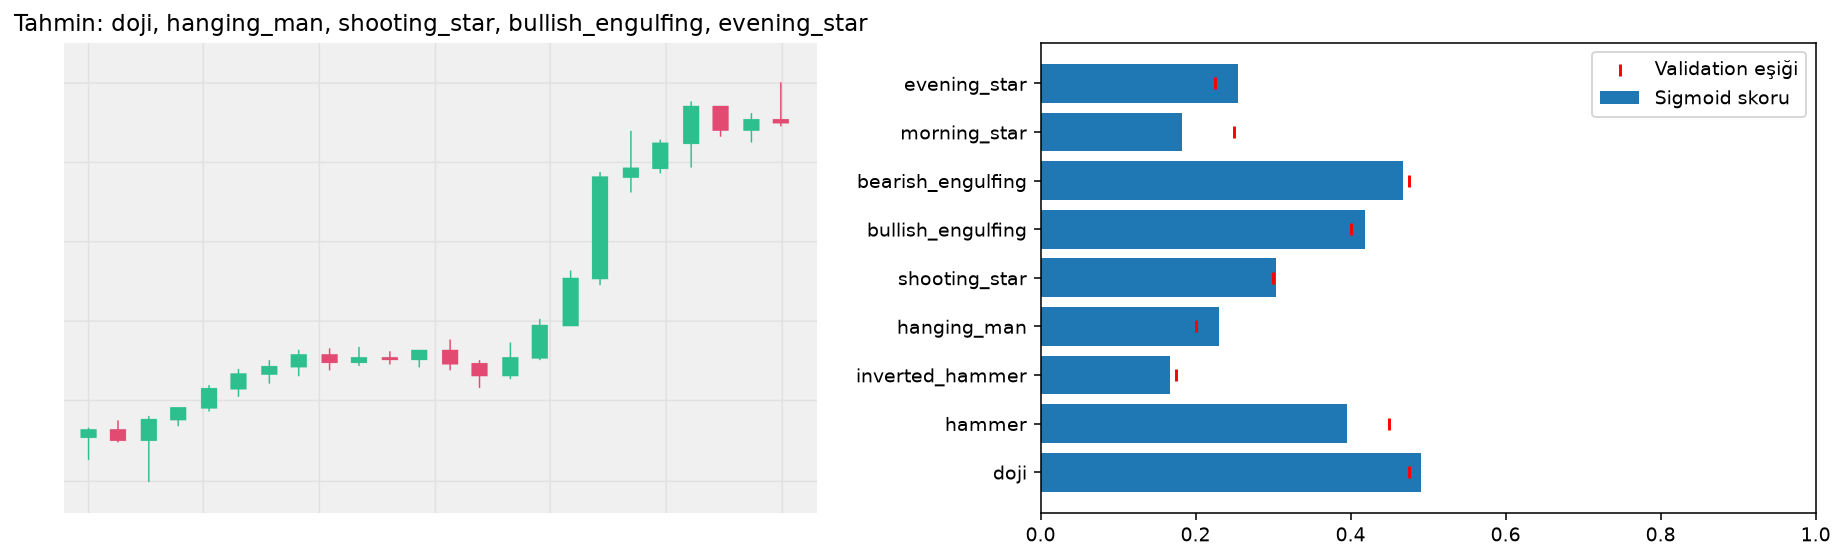

In [23]:
example_result = export_prediction_example(config, parts, checkpoint_path)
MODEL_PATH = OUT / "best_model.pt"
IMAGE_PATH = OUT / "single_input.png"  # Kendi dosyanızı burada seçebilirsiniz.

loaded_model, saved = load_model(MODEL_PATH, device="cpu")
print("Yüklenen epoch:", saved["best_epoch"])
print("Sınıflar:", saved["classes"])
print("Giriş boyutu:", saved["image_size"])
prediction = predict_image(MODEL_PATH, IMAGE_PATH)
print("Tahmin:", prediction["labels"])
display(pd.DataFrame(prediction["scores"]))
display(Image(filename=str(FIG / "single_prediction.png")))

## 10. Başka bir resimde tahmin — sonraki oturumda da kullan

Aşağıdaki `MODEL_PATH` ve `IMAGE_PATH` değerlerini kendi dosyalarınızla değiştirin.
Yeni oturumda eğitim yapmak gerekmez: kütüphane, ortak tanımlar, görüntü okuma,
ön işleme, CNN mimarisi, `load_model` ve `predict_image` tanım hücrelerini çalıştırın.
Ardından bu hücreyi kendi kayıtlı model ve görüntü yollarınızla çalıştırın.

In [24]:
# Aynı oturumda yukarıdaki örnek yollarını kullanır.
# Sonraki oturumda bu iki satıra kayıtlı model ve görüntünüzün tam yolunu yazın.
# MODEL_PATH = ROOT / "outputs/deney_klasoru/best_model.pt"
# IMAGE_PATH = ROOT / "kendi_grafigim.png"
result = predict_image(MODEL_PATH, IMAGE_PATH, device="cpu")
print("Tahmin:", result["labels"])
display(pd.DataFrame(result["scores"]))

Tahmin: ['doji', 'hanging_man', 'shooting_star', 'bullish_engulfing', 'evening_star']


,class,score,threshold,predicted
0,doji,0.491018,0.475,True
1,hammer,0.395448,0.450,False
2,inverted_hammer,0.166970,0.175,False
3,hanging_man,0.230541,0.200,True
4,shooting_star,0.303648,0.300,True
5,bullish_engulfing,0.419227,0.400,True
6,bearish_engulfing,0.467627,0.475,False
7,morning_star,0.182197,0.250,False
8,evening_star,0.255348,0.225,True


## 11. Deney dosyaları ve yorumlama
`best_model.pt`: ağırlıklar, sınıf sırası, giriş boyutu ve validation eşikleri.
`history.csv`: train/validation loss ve F1. `test_metrics.json` ve
`test_per_class.csv`: ölçümler. `test_predictions.csv`: tek tek sonuçlar.
`test_probabilities.npz`: gerçek etiketler ve skorlar. `figures/`: tüm PNG'ler.
`config.json`, `environment.json`, `used_manifest.csv`: deneyin ayar ve örnekleri.

QUICK_RUN sonuçları yalnız akış denemesidir. Tam veri başarısı veya uzman
etiketli dış veri başarısı olarak kullanılmaz. Bu deney finansal getiri ölçmez.

Uygulama referansları: [PyTorch model kaydetme/yükleme](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html),
[BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

In [25]:
print("Deney klasörü:", OUT)
display(pd.DataFrame({"dosya": sorted(p.name for p in OUT.iterdir())}))

Deney klasörü: C:\Users\sekocan\Desktop\yükseklisans-donem-2\goruntu-isleme\outputs\cnn_notebook_20261027_065451


,dosya
0,TEST_OZETI.md
1,best_model.pt
2,class_counts.csv
3,clean_manifest.csv
4,cleaned_raw
5,config.json
6,data_report.json
7,environment.json
8,figures
9,history.csv
